# Task 2 – Ising Spin Glass Optimisation
Portfolio optimisation of 20 US stocks (2000–2025): the Task 1 QUBO re-written as an Ising spin-glass Hamiltonian and solved, then compared with Task 1 (QUBO + simulated annealing, MIQP).

Follows `Task2_Ising_Roadmap.docx` step by step (Steps 1–8, required parts only; the optional items 4c, 4d, the k = 1…20 repeat, the J heat map and the 10-lowest-states table are not included).

## Step 1 – Freeze the inputs
One shared settings cell: same data, μ, Σ, λ, k and P as Task 1 (identical code to the Task 1 notebook). Any difference in the results below comes only from the Ising formulation or the solver.

In [1]:
# STEP 1 | SHARED SETTINGS (same inputs as Task 1)
import os, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from IPython.display import display, Markdown
import dimod
from dwave.samplers import SimulatedAnnealingSampler

warnings.filterwarnings("ignore")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

DATA_FILE  = "us_stock_data/adj_close_wide.csv"
OUT_DIR    = "ising_outputs"
START, END = "2000-01-01", "2026-01-01"
TD         = 252
RF         = 0.0
MAX_W      = 0.30          # weight cap used for the efficient frontier chart (as in Task 1)
K          = 6             # stocks to select
SEED       = 42
MC_N, MC_RUNS, MC_SEED = 5000, 200, SEED + 7      # Monte Carlo penalty estimate (as in Task 1)
X_AXIS     = "variance"
os.makedirs(OUT_DIR, exist_ok=True)
def savefig(name): plt.savefig(f"{OUT_DIR}/{name}.png", dpi=300, bbox_inches="tight")

# data, mu, Sigma (computed once)
prices  = pd.read_csv(DATA_FILE, index_col="Date", parse_dates=True).sort_index().loc[START:END]
returns = prices.pct_change().iloc[1:].dropna()
tickers = list(returns.columns); N = len(tickers)
mu      = returns.mean().to_numpy() * TD
Sigma   = returns.cov().to_numpy() * TD
print(f"{N} stocks | {returns.index[0].date()} to {returns.index[-1].date()} | {len(returns)} daily returns")

# portfolio helpers (identical to Task 1)
def mv_objective(w, mu=mu, Sigma=Sigma, lam=None):
    lam = LAMBDA if lam is None else lam
    return 0.5 * lam * w @ Sigma @ w - mu @ w

def port_stats(w, mu=mu, Sigma=Sigma):
    """(expected return, variance, volatility, Sharpe)"""
    ret, var = float(mu @ w), float(w @ Sigma @ w)
    return ret, var, np.sqrt(var), (ret - RF) / np.sqrt(var)

def _slsqp(fun, jac, n, cap, starts):
    cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)}]
    best = None
    for w0 in starts:
        res = minimize(fun, w0, jac=jac, method="SLSQP", bounds=[(0.0, cap)] * n,
                       constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    w = np.clip(best.x, 0.0, cap)
    return w / w.sum()

def min_variance(Sigma, cap):
    n = len(Sigma)
    return _slsqp(lambda w: w @ Sigma @ w, lambda w: 2 * Sigma @ w, n, cap, [np.full(n, 1.0 / n)])

def max_sharpe(mu, Sigma, cap, rf=RF):
    n = len(mu)
    def fun(w): return -(mu @ w - rf) / np.sqrt(w @ Sigma @ w)
    def jac(w):
        s = np.sqrt(w @ Sigma @ w)
        return -(mu / s - (mu @ w - rf) * (Sigma @ w) / s ** 3)
    return _slsqp(fun, jac, n, cap, [np.full(n, 1.0 / n), min_variance(Sigma, cap)])

def frontier_points(mu, Sigma, cap, n_pts=80):
    """Long-only efficient frontier. Returns arrays (variance, return)."""
    n = len(mu)
    w_min = min_variance(Sigma, cap)
    order, w_hi, left = np.argsort(-mu), np.zeros(n), 1.0
    for i in order:
        take = min(cap, left); w_hi[i] = take; left -= take
        if left <= 1e-12: break
    pts = []
    for tr in np.linspace(mu @ w_min, mu @ w_hi, n_pts)[:-1]:
        cons = [{"type": "eq", "fun": lambda w: np.sum(w) - 1.0, "jac": lambda w: np.ones(n)},
                {"type": "eq", "fun": lambda w, tr=tr: mu @ w - tr, "jac": lambda w: mu}]
        res = minimize(lambda w: w @ Sigma @ w, w_min, jac=lambda w: 2 * Sigma @ w, method="SLSQP",
                       bounds=[(0.0, cap)] * n, constraints=cons, options={"maxiter": 1000, "ftol": 1e-12})
        if res.success:
            pts.append((res.fun, tr))
    pts.append((w_hi @ Sigma @ w_hi, mu @ w_hi))
    pts = np.array(pts); pts = pts[np.argsort(pts[:, 0])]
    return pts[:, 0], np.maximum.accumulate(pts[:, 1])

# lambda (from the max-Sharpe portfolio, as in Task 1)
w_maxsh = max_sharpe(mu, Sigma, MAX_W)
r_t, v_t, _, _ = port_stats(w_maxsh)
LAMBDA = (r_t - RF) / v_t

# penalty P for k = 6 (Monte Carlo, Algorithm 1 / Eq. 8, largest estimate over all runs; as in Task 1)
def mc_binary_samples(n, m, rng):
    card = rng.integers(0, n + 1, size=m)
    rank = np.argsort(np.argsort(rng.random((m, n)), axis=1), axis=1)
    return (rank < card[:, None]).astype(float)

def penalty_lower_bound(q, lin, s, k, lam):
    f = 0.5 * lam / k ** 2 * q - lin / k
    viol = (s - k) ** 2
    v_min = viol.min()
    f_from = f[viol == v_min].min()
    m = (f < f_from) & (viol > v_min)
    if not m.any():
        return 0.0
    return ((f_from - f[m]) / (viol[m] - v_min)).max()

rng_mc = np.random.default_rng(MC_SEED)
mc_p = np.zeros(MC_RUNS)
for run in range(MC_RUNS):
    Xs = mc_binary_samples(N, MC_N, rng_mc)
    mc_p[run] = penalty_lower_bound(np.einsum("ri,ij,rj->r", Xs, Sigma, Xs), Xs @ mu, Xs.sum(axis=1), K, LAMBDA)
P = mc_p.max()

# QUBO builder (same formula as Task 1):  H(x) = x'Qx + CONST
def build_Q(P):
    Q = 0.5 * LAMBDA / K ** 2 * Sigma - np.diag(mu / K) + P * (np.ones((N, N)) - 2 * K * np.eye(N))
    return Q, P * K ** 2

print(f"lambda = {LAMBDA:.4f}   |   P (k = {K}) = {P:.4f}   |   k = {K}   |   N = {N}")
assert abs(LAMBDA - 5.1422) < 5e-5 and abs(P - 0.0256) < 5e-5, "inputs differ from Task 1"
print("check: lambda = 5.1422 and P = 0.0256 -> identical to the Task 1 inputs")

Q, CONST = build_Q(P)

20 stocks | 2000-01-04 to 2025-12-31 | 6538 daily returns
lambda = 5.1422   |   P (k = 6) = 0.0256   |   k = 6   |   N = 20
check: lambda = 5.1422 and P = 0.0256 -> identical to the Task 1 inputs


## Step 2 – Convert QUBO to Ising (the maths)
Substituting $x_i=(1+s_i)/2$ in $H(x)=x^\top Qx+\text{const}$ (symmetric $Q$, linear terms on the diagonal) gives

$$H(s)=\sum_{i<j}J_{ij}\,s_is_j+\sum_i h_i\,s_i+C,\qquad J_{ij}=\tfrac12 Q_{ij},\quad h_i=\tfrac12\sum_j Q_{ij},\quad C=\tfrac14\sum_{ij}Q_{ij}+\tfrac14\sum_i Q_{ii}+Pk^2 .$$

Bit 1 (stock selected) ↔ spin +1 (up). The constraint "exactly k stocks" becomes a fixed magnetisation $\sum_i s_i = 2k-N$.

In [2]:
# STEP 2 | hand-coded QUBO -> Ising conversion
def qubo_to_ising_manual(Q, const):
    J = np.triu(Q / 2.0, 1)                    # J_ij = Q_ij / 2   (i < j)
    h = 0.5 * Q.sum(axis=1)                    # h_i  = 1/2 * sum_j Q_ij
    C = 0.25 * Q.sum() + 0.25 * np.trace(Q) + const
    return J, h, C

J, h, C = qubo_to_ising_manual(Q, CONST)
MAGNETISATION = 2 * K - N
iu = np.triu_indices(N, 1)

print(f"{len(iu[0])} spin-spin couplings (fully connected, N = {N})")
print(f"J_ij : {(J[iu] > 0).sum()} positive (antiferromagnetic), {(J[iu] < 0).sum()} negative (ferromagnetic) | range [{J[iu].min():.5f}, {J[iu].max():.5f}]")
print(f"h_i  : {(h > 0).sum()} positive, {(h < 0).sum()} negative | range [{h.min():.5f}, {h.max():.5f}]")
Js = J + J.T
frustrated = sum(Js[i, j] * Js[j, l] * Js[i, l] > 0 for i, j, l in itertools.combinations(range(N), 3))
print(f"frustrated triangles (J_ij J_jk J_ik > 0): {frustrated} of {len(list(itertools.combinations(range(N), 3)))}")
print(f"constant C = {C:.6f}")
print(f"fixed magnetisation: sum(s) = 2k - N = {MAGNETISATION}  ({K} spins up, {N - K} down)")

print("\nLocal fields h (from expected returns + penalty):")
display(pd.Series(h, index=tickers, name="h_i").round(5).to_frame().T)
print("Couplings J (upper triangle, from covariance + penalty):")
display(pd.DataFrame(J, index=tickers, columns=tickers).round(4))

190 spin-spin couplings (fully connected, N = 20)
J_ij : 190 positive (antiferromagnetic), 0 negative (ferromagnetic) | range [0.01317, 0.01768]
h_i  : 20 positive, 0 negative | range [0.10808, 0.14399]
frustrated triangles (J_ij J_jk J_ik > 0): 1140 of 1140
constant C = 0.624832
fixed magnetisation: sum(s) = 2k - N = -8  (6 spins up, 14 down)

Local fields h (from expected returns + penalty):


,MSFT,AAPL,NVDA,AMZN,INTC,WMT,KO,DIS,PG,IBM,MCD,JPM,GS,MS,AXP,BAC,JNJ,XOM,UNH,BRK-B
h_i,0.12179,0.11225,0.11582,0.11994,0.13381,0.11092,0.11073,0.12464,0.10941,0.11978,0.10912,0.1317,0.13083,0.14399,0.13089,0.13687,0.10808,0.11658,0.10924,0.11215


Couplings J (upper triangle, from covariance + penalty):


,MSFT,AAPL,NVDA,AMZN,INTC,WMT,KO,DIS,PG,IBM,MCD,JPM,GS,MS,AXP,BAC,JNJ,XOM,UNH,BRK-B
MSFT,0.0,0.0148,0.0159,0.0151,0.0151,0.0137,0.0135,0.0143,0.0134,0.0141,0.0136,0.0146,0.0146,0.0152,0.0146,0.0145,0.0134,0.0138,0.0138,0.0136
AAPL,0.0,0.0000,0.0162,0.0153,0.0153,0.0137,0.0135,0.0143,0.0134,0.0142,0.0136,0.0146,0.0147,0.0152,0.0146,0.0147,0.0134,0.0138,0.0138,0.0136
NVDA,0.0,0.0000,0.0000,0.0165,0.0169,0.0138,0.0134,0.0151,0.0132,0.0149,0.0138,0.0154,0.0157,0.0165,0.0153,0.0153,0.0133,0.0141,0.0140,0.0140
AMZN,0.0,0.0000,0.0000,0.0000,0.0154,0.0137,0.0133,0.0147,0.0133,0.0142,0.0136,0.0149,0.0150,0.0156,0.0148,0.0147,0.0133,0.0137,0.0138,0.0137
INTC,0.0,0.0000,0.0000,0.0000,0.0000,0.0137,0.0135,0.0145,0.0135,0.0145,0.0136,0.0150,0.0150,0.0156,0.0150,0.0150,0.0135,0.0140,0.0138,0.0138
WMT,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0134,0.0136,0.0135,0.0135,0.0134,0.0138,0.0138,0.0141,0.0138,0.0138,0.0133,0.0134,0.0135,0.0133
KO,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0136,0.0136,0.0134,0.0135,0.0137,0.0135,0.0139,0.0138,0.0137,0.0134,0.0136,0.0136,0.0134
DIS,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0135,0.0140,0.0137,0.0148,0.0148,0.0154,0.0150,0.0149,0.0135,0.0140,0.0138,0.0138
PG,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0134,0.0134,0.0136,0.0135,0.0138,0.0137,0.0137,0.0135,0.0134,0.0135,0.0133
IBM,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0135,0.0144,0.0143,0.0148,0.0143,0.0144,0.0134,0.0138,0.0136,0.0136


## Step 3 – Build the Ising model in code and validate it
Route A: the dimod `BinaryQuadraticModel` from the Task 1 QUBO converted with `bqm.to_ising()`. Route B: the hand-coded formulas of Step 2. Both must give the same h, J and C. Then the validation test over all 2²⁰ states.

In [3]:
# STEP 3 | Route A: dimod BQM -> to_ising()
bqm_qubo = dimod.BinaryQuadraticModel.from_qubo(
    {(i, j): (Q[i, j] + Q[j, i] if i != j else Q[i, i]) for i in range(N) for j in range(i, N)}, offset=CONST)
h_d, J_d, off_d = bqm_qubo.to_ising()
bqm_ising = dimod.BinaryQuadraticModel.from_ising(h_d, J_d, off_d)          # the SPIN model that is sampled later

# compare with the hand-coded Route B (dimod may store a pair as (i,j) or (j,i))
Jd_mat = np.zeros((N, N))
for (i, j), v in J_d.items():
    Jd_mat[min(i, j), max(i, j)] = v
d_h = max(abs(h_d[i] - h[i]) for i in range(N)); d_J = np.abs(Jd_mat - J).max(); d_C = abs(off_d - C)
print(f"dimod vs hand-coded:  max|dh| = {d_h:.1e} | max|dJ| = {d_J:.1e} | |dC| = {d_C:.1e}")
assert d_h < 1e-12 and d_J < 1e-12 and d_C < 1e-12
print("Route A and Route B agree: h, J and C are verified.\n")

def qubo_energy(X):  return np.einsum("ui,ij,uj->u", X, Q, X) + CONST
def ising_energy(S): return S @ h + ((S @ J) * S).sum(axis=1) + C

# Validation 1: all 2^20 states, Ising energy = QUBO energy (chunks of 2^16)
t0 = time.time(); max_diff = 0.0; E_min, s_min = np.inf, None
for start in range(0, 2 ** N, 2 ** 16):
    idx = np.arange(start, start + 2 ** 16)
    X = ((idx[:, None] >> np.arange(N)) & 1).astype(float); S = 2 * X - 1
    Eq, Ei = qubo_energy(X), ising_energy(S)
    max_diff = max(max_diff, np.abs(Eq - Ei).max())
    if Ei.min() < E_min: E_min, s_min = Ei.min(), X[Ei.argmin()].copy()
print(f"Validation 1 - all {2 ** N:,} states: max |E_Ising - E_QUBO| = {max_diff:.2e}   ({time.time() - t0:.1f} s)")
assert max_diff < 1e-10

# Validation 2: the 38,760 feasible states (exactly 6 stocks): E_Ising = Markowitz objective 1/2*lam*w'Sigma w - mu'w
combos = np.array(list(itertools.combinations(range(N), K)))
Xf = np.zeros((len(combos), N)); Xf[np.arange(len(combos))[:, None], combos] = 1.0
Wf = Xf / K
obj_f = 0.5 * LAMBDA * np.einsum("ui,ij,uj->u", Wf, Sigma, Wf) - Wf @ mu
Ef = ising_energy(2 * Xf - 1)
print(f"Validation 2 - {len(combos):,} feasible states: max |E_Ising - Markowitz objective| = {np.abs(Ef - obj_f).max():.2e}")
assert np.abs(Ef - obj_f).max() < 1e-10
print("Verified Ising Hamiltonian.")

dimod vs hand-coded:  max|dh| = 8.3e-17 | max|dJ| = 0.0e+00 | |dC| = 1.1e-16
Route A and Route B agree: h, J and C are verified.

Validation 1 - all 1,048,576 states: max |E_Ising - E_QUBO| = 4.44e-15   (1.2 s)
Validation 2 - 38,760 feasible states: max |E_Ising - Markowitz objective| = 5.00e-16
Verified Ising Hamiltonian.


## Step 4 – Solve the Ising model
**4a. Exact reference** – brute force over all spin states with Σs = −8 (the 38,760 feasible states). The global minimum over all 2²⁰ states from the validation above is used as a cross-check.

In [4]:
# STEP 4a | exact ground state
t0 = time.time()
combos_ex = np.array(list(itertools.combinations(range(N), K)))             # every way to put 6 spins up
S_ex = -np.ones((len(combos_ex), N)); S_ex[np.arange(len(combos_ex))[:, None], combos_ex] = 1.0   # all states with sum(s) = -8
E_feas = ising_energy(S_ex)                                                  # Ising energy of each
i_gs = int(np.argmin(E_feas))
x_gs = Xf[i_gs]; sel_gs = np.flatnonzero(x_gs)
t_exact = time.time() - t0
assert np.allclose(E_feas, Ef)
E_GS = float(E_feas[i_gs]); F_EX = float(obj_f[i_gs])
E_sorted = np.sort(E_feas)

# the QUBO exhaustive optimum (same 38,760 states) for the comparison
i_q = int(np.argmin(qubo_energy(Xf)))
print(f"Ising ground state (sum s = {MAGNETISATION}): " + ", ".join(tickers[i] for i in sel_gs))
print(f"ground-state energy      : {E_GS:.6f}")
print(f"Markowitz objective      : {F_EX:.6f}   (equal to the Ising energy)")
print(f"gap to first excited state: {E_sorted[1] - E_sorted[0]:.6f}")
print(f"same state as global minimum over all 2^20 spin states : {np.array_equal(s_min, x_gs)} (E = {E_min:.6f})")
print(f"same portfolio as the QUBO exhaustive optimum          : {i_q == i_gs}")
print(f"enumeration time: {t_exact * 1000:.1f} ms")
assert np.array_equal(s_min, x_gs) and i_q == i_gs

Ising ground state (sum s = -8): AAPL, NVDA, MCD, JNJ, UNH, BRK-B
ground-state energy      : -0.111866
Markowitz objective      : -0.111866   (equal to the Ising energy)
gap to first excited state: 0.002315
same state as global minimum over all 2^20 spin states : True (E = -0.111866)
same portfolio as the QUBO exhaustive optimum          : True
enumeration time: 36.7 ms


**4b. Ising simulated annealing** – Metropolis single-spin-flip annealing on h and J, using the `dwave-samplers` `SimulatedAnnealingSampler` on the SPIN model, with the same budget as the Task 1 D-Wave local SA (1000 reads × 1000 sweeps, seed 42). The Task 1 QUBO run is repeated alongside it as a check of the 4.3% benchmark.

In [5]:
# STEP 4b | Ising simulated annealing
NUM_READS, NUM_SWEEPS = 1000, 1000
col_order = lambda ss: [list(ss.variables).index(i) for i in range(N)]

t0 = time.time()
ss_ising = SimulatedAnnealingSampler().sample(bqm_ising, num_reads=NUM_READS, num_sweeps=NUM_SWEEPS, seed=SEED)
t_ising = time.time() - t0
t0 = time.time()
ss_qubo = SimulatedAnnealingSampler().sample(bqm_qubo, num_reads=NUM_READS, num_sweeps=NUM_SWEEPS, seed=SEED)   # Task 1 benchmark run
t_qubo = time.time() - t0

S_ising = np.array(ss_ising.record.sample)[:, col_order(ss_ising)].astype(float)      # spins in {-1,+1}
E_ising_reads = np.array(ss_ising.record.energy)
assert np.allclose(E_ising_reads, ising_energy(S_ising), atol=1e-9), "sampler energy != Ising energy"
print(f"Ising SA  : {NUM_READS} reads x {NUM_SWEEPS} sweeps in {t_ising:.2f} s | lowest energy found {E_ising_reads.min():.6f} (exact {E_GS:.6f})")
print(f"QUBO SA   : {NUM_READS} reads x {NUM_SWEEPS} sweeps in {t_qubo:.2f} s (Task 1 D-Wave local SA, re-run)")

Ising SA  : 1000 reads x 1000 sweeps in 0.41 s | lowest energy found -0.111866 (exact -0.111866)
QUBO SA   : 1000 reads x 1000 sweeps in 0.38 s (Task 1 D-Wave local SA, re-run)


## Step 5 – Decode and evaluate
Spins are converted back with $x=(1+s)/2$; only samples with exactly k = 6 stocks are kept. Every portfolio is scored with `port_stats` and `mv_objective`, exactly as in Task 1.

In [6]:
# STEP 5 | decode + evaluate
def score_reads(X):
    """X: reads x N bits. Returns feasible mask and the equal-weight Markowitz objective of every read."""
    feas = X.sum(axis=1) == K
    W = X / K
    obj = 0.5 * LAMBDA * np.einsum("ui,ij,uj->u", W, Sigma, W) - W @ mu
    return feas, obj

X_ising = (1 + S_ising) / 2                                   # x = (1 + s)/2
feas_i, obj_i = score_reads(X_ising)
hit_i = feas_i & (obj_i <= F_EX + 1e-10)

best_i = int(np.argmin(np.where(feas_i, obj_i, np.inf)))
w_ising = X_ising[best_i] / K
r_i, v_i, s_i, sh_i = port_stats(w_ising)
obj_best_i = mv_objective(w_ising)

# Task 1 benchmark run decoded the same way
cq = col_order(ss_qubo); X_q = np.array(ss_qubo.record.sample)[:, cq].astype(float)
feas_q, obj_q = score_reads(X_q); hit_q = feas_q & (obj_q <= F_EX + 1e-10)

print(f"Ising SA (seed {SEED}): reads with exactly {K} stocks {feas_i.mean() * 100:.1f}% | reads at the exact optimum {hit_i.mean() * 100:.1f}% | distinct states {len(np.unique(X_ising, axis=0))}")
print(f"QUBO SA  (seed {SEED}): reads with exactly {K} stocks {feas_q.mean() * 100:.1f}% | reads at the exact optimum {hit_q.mean() * 100:.1f}%   <- Task 1 benchmark (4.3%)")
print("=" * 78)
print("Ising SA best portfolio: " + ", ".join(tickers[i] for i in np.flatnonzero(X_ising[best_i])) + f"  -> {100 / K:.2f}% each")
print(f"return {r_i * 100:.2f}% | variance {v_i:.4f} | volatility {s_i * 100:.2f}% | Sharpe {sh_i:.3f} | objective {obj_best_i:.4f}")
print(f"same stocks as the exact ground state: {set(np.flatnonzero(X_ising[best_i])) == set(sel_gs)}")
print("=" * 78)

r_e, v_e, s_e, sh_e = port_stats(x_gs / K)

Ising SA (seed 42): reads with exactly 6 stocks 99.1% | reads at the exact optimum 3.2% | distinct states 432
QUBO SA  (seed 42): reads with exactly 6 stocks 99.8% | reads at the exact optimum 4.3%   <- Task 1 benchmark (4.3%)
Ising SA best portfolio: AAPL, NVDA, MCD, JNJ, UNH, BRK-B  -> 16.67% each
return 22.26% | variance 0.0431 | volatility 20.75% | Sharpe 1.073 | objective -0.1119
same stocks as the exact ground state: True


## Step 6 – Comparison experiments
Each stochastic solver is repeated over **30 random seeds** (1000 reads × 1000 sweeps per seed). Metrics: best objective, gap to the exact optimum, % of reads that hit the optimum, % of feasible reads, runtime. The QUBO model (Task 1 D-Wave local SA) is run with the same seeds as a like-for-like reference for the 4.3% benchmark. Sensitivity: number of sweeps (10, 50, 150, 1000) and penalty P (0.5×, 1×, 2×).

In [7]:
# STEP 6 | experiments
SEEDS = list(range(1, 31))

def run_config(bqm, seeds, sweeps, reads=1000):
    rows = []
    for sd in seeds:
        t0 = time.time()
        ss = SimulatedAnnealingSampler().sample(bqm, num_reads=reads, num_sweeps=sweeps, seed=sd)
        dt = time.time() - t0
        Z = np.array(ss.record.sample)[:, col_order(ss)].astype(float)
        X = (1 + Z) / 2 if ss.vartype is dimod.SPIN else Z
        feas, obj = score_reads(X)
        best = obj[feas].min() if feas.any() else np.nan
        rows.append({"seed": sd, "Best objective": best, "Gap to exact": best - F_EX,
                     "Reads at optimum (%)": (feas & (obj <= F_EX + 1e-10)).mean() * 100,
                     "Feasible reads (%)": feas.mean() * 100, "Runtime (s)": dt,
                     "Best read = optimum": bool(feas.any() and best <= F_EX + 1e-10)})
    return pd.DataFrame(rows)

def summarise(df):
    return pd.Series({"Best objective (mean)": df["Best objective"].mean(),
                      "Gap to exact (mean)": df["Gap to exact"].mean(),
                      "Reads at optimum % (mean)": df["Reads at optimum (%)"].mean(),
                      "Reads at optimum % (std)": df["Reads at optimum (%)"].std(ddof=1),
                      "Reads at optimum % (min-max)": f"{df['Reads at optimum (%)'].min():.1f} - {df['Reads at optimum (%)'].max():.1f}",
                      "Feasible reads % (mean)": df["Feasible reads (%)"].mean(),
                      "Feasible reads % (std)": df["Feasible reads (%)"].std(ddof=1),
                      f"Seeds whose best read is optimal (of {len(df)})": int(df["Best read = optimum"].sum()),
                      "Runtime s (mean)": df["Runtime (s)"].mean()})

# 6a. headline: 1000 reads x 1000 sweeps, 30 seeds, Ising vs QUBO (same seeds)
res_ising = run_config(bqm_ising, SEEDS, 1000)
res_qubo  = run_config(bqm_qubo,  SEEDS, 1000)
tab_main = pd.DataFrame({"Ising SA (SPIN model)": summarise(res_ising), "QUBO SA (Task 1 D-Wave local SA)": summarise(res_qubo)})
print("6a. 30 seeds x (1000 reads x 1000 sweeps), exact objective =", round(F_EX, 6))
display(tab_main)

# 6b. sensitivity to the number of sweeps (Ising model, P = 1x)
SWEEPS = [10, 50, 150, 1000]
res_sweeps = {sw: run_config(bqm_ising, SEEDS, sw) for sw in SWEEPS}
tab_sweeps = pd.DataFrame({sw: summarise(df) for sw, df in res_sweeps.items()}).T.rename_axis("sweeps")
print("6b. Sensitivity to the number of sweeps (Ising, 1000 reads, 30 seeds)")
display(tab_sweeps[["Reads at optimum % (mean)", "Reads at optimum % (std)", "Feasible reads % (mean)",
                    f"Seeds whose best read is optimal (of {len(SEEDS)})", "Gap to exact (mean)", "Runtime s (mean)"]])

# 6c. sensitivity to the penalty P (Ising model, 1000 sweeps)
def ising_bqm_for_P(Pm):
    Qm, Cm = build_Q(Pm)
    b = dimod.BinaryQuadraticModel.from_qubo({(i, j): (Qm[i, j] + Qm[j, i] if i != j else Qm[i, i])
                                              for i in range(N) for j in range(i, N)}, offset=Cm)
    hh, JJ, oo = b.to_ising()
    return dimod.BinaryQuadraticModel.from_ising(hh, JJ, oo)

P_MULTS = [0.5, 1.0, 2.0]
res_P = {m: run_config(ising_bqm_for_P(P * m), SEEDS, 1000) for m in P_MULTS}
tab_P = pd.DataFrame({f"{m}x (P = {P * m:.4f})": summarise(df) for m, df in res_P.items()}).T.rename_axis("penalty")
print("6c. Sensitivity to the penalty P (Ising, 1000 reads x 1000 sweeps, 30 seeds)")
display(tab_P[["Reads at optimum % (mean)", "Reads at optimum % (std)", "Feasible reads % (mean)",
               f"Seeds whose best read is optimal (of {len(SEEDS)})", "Gap to exact (mean)", "Runtime s (mean)"]])

6a. 30 seeds x (1000 reads x 1000 sweeps), exact objective = -0.111866


,Ising SA (SPIN model),QUBO SA (Task 1 D-Wave local SA)
Best objective (mean),-0.111866,-0.111866
Gap to exact (mean),0.0,0.0
Reads at optimum % (mean),3.743333,3.85
Reads at optimum % (std),0.620724,0.442368
Reads at optimum % (min-max),3.0 - 5.1,3.0 - 4.7
Feasible reads % (mean),99.243333,99.286667
Feasible reads % (std),0.29558,0.252891
Seeds whose best read is optimal (of 30),30,30
Runtime s (mean),0.385542,0.372316


6b. Sensitivity to the number of sweeps (Ising, 1000 reads, 30 seeds)


,Reads at optimum % (mean),Reads at optimum % (std),Feasible reads % (mean),Seeds whose best read is optimal (of 30),Gap to exact (mean),Runtime s (mean)
sweeps,,,,,,
10,0.246667,0.150249,98.716667,29,0.000077,0.005551
50,1.24,0.370089,99.18,30,0.0,0.02082
150,2.106667,0.433855,99.1,30,0.0,0.059501
1000,3.743333,0.620724,99.243333,30,0.0,0.371928


6c. Sensitivity to the penalty P (Ising, 1000 reads x 1000 sweeps, 30 seeds)


,Reads at optimum % (mean),Reads at optimum % (std),Feasible reads % (mean),Seeds whose best read is optimal (of 30),Gap to exact (mean),Runtime s (mean)
penalty,,,,,,
0.5x (P = 0.0128),15.086667,1.135853,99.423333,30,0.0,0.380483
1.0x (P = 0.0256),3.743333,0.620724,99.243333,30,0.0,0.383711
2.0x (P = 0.0512),0.43,0.21359,99.18,29,0.000077,0.369377


## Step 7 – Charts and spin-glass diagnostics

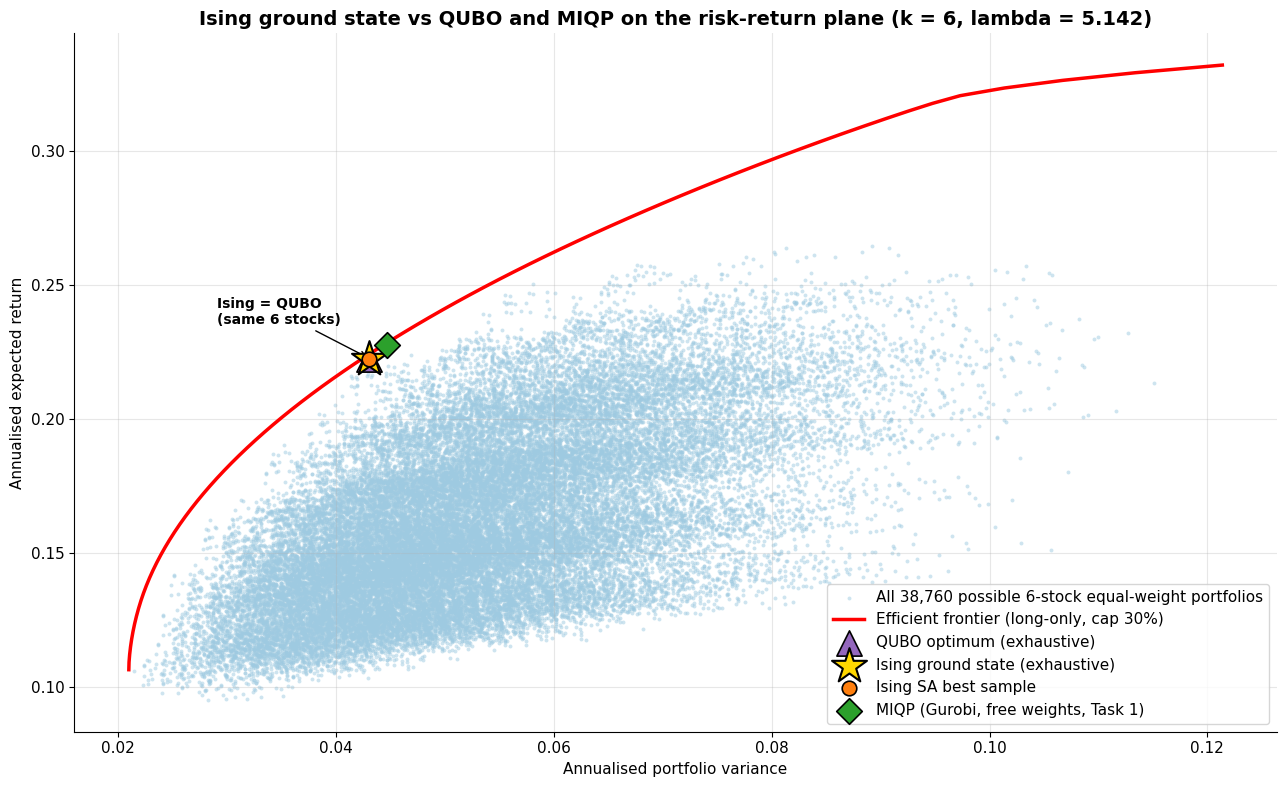

In [8]:
# STEP 7 | chart 1: risk-return map (Ising / QUBO / MIQP vs the efficient frontier)
f_var, f_ret = frontier_points(mu, Sigma, MAX_W)
xs = lambda v: np.asarray(v, dtype=float) if X_AXIS == "variance" else np.sqrt(np.asarray(v, dtype=float))
XLABEL = "Annualised portfolio variance" if X_AXIS == "variance" else "Annualised volatility"

# Task 1 MIQP portfolio (values from the roadmap): return 22.76%, volatility 21.15%
miqp_ret, miqp_vol = 0.2276, 0.2115
MIQP_W = {"UNH": 20.3, "AAPL": 19.3, "JNJ": 17.7, "NVDA": 16.0, "MCD": 15.2, "BRK-B": 11.5}

rc = mu[combos].mean(axis=1); vc = Sigma[combos[:, :, None], combos[:, None, :]].sum(axis=(1, 2)) / K ** 2
w_q = Xf[i_q] / K; r_q, v_q, _, _ = port_stats(w_q)

fig, ax = plt.subplots(figsize=(13, 8))
ax.scatter(xs(vc), rc, s=8, color="#9ecae1", alpha=0.5, linewidths=0, label=f"All {len(combos):,} possible {K}-stock equal-weight portfolios")
ax.plot(xs(f_var), f_ret, color="red", lw=2.5, label=f"Efficient frontier (long-only, cap {MAX_W:.0%})")
ax.scatter(xs(v_q), r_q, marker="^", s=330, color="#9467bd", edgecolor="black", linewidths=1.2, zorder=5, label="QUBO optimum (exhaustive)")
ax.scatter(xs(v_e), r_e, marker="*", s=700, color="gold", edgecolor="black", linewidths=1.5, zorder=6, label="Ising ground state (exhaustive)")
ax.scatter(xs(v_i), r_i, marker="o", s=110, color="#ff7f0e", edgecolor="black", linewidths=1.2, zorder=7, label="Ising SA best sample")
ax.scatter(xs(miqp_vol ** 2), miqp_ret, marker="D", s=170, color="#2ca02c", edgecolor="black", linewidths=1.2, zorder=6, label="MIQP (Gurobi, free weights, Task 1)")
ax.annotate("Ising = QUBO\n(same 6 stocks)", (xs(v_e), r_e), xytext=(-110, 25), textcoords="offset points", fontsize=10, fontweight="bold",
            arrowprops=dict(arrowstyle="->", lw=1))
ax.set_xlabel(XLABEL); ax.set_ylabel("Annualised expected return"); ax.grid(True, alpha=0.3); ax.legend(loc="lower right")
ax.set_title(f"Ising ground state vs QUBO and MIQP on the risk-return plane (k = {K}, lambda = {LAMBDA:.3f})", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("ising_risk_return_map"); plt.show()

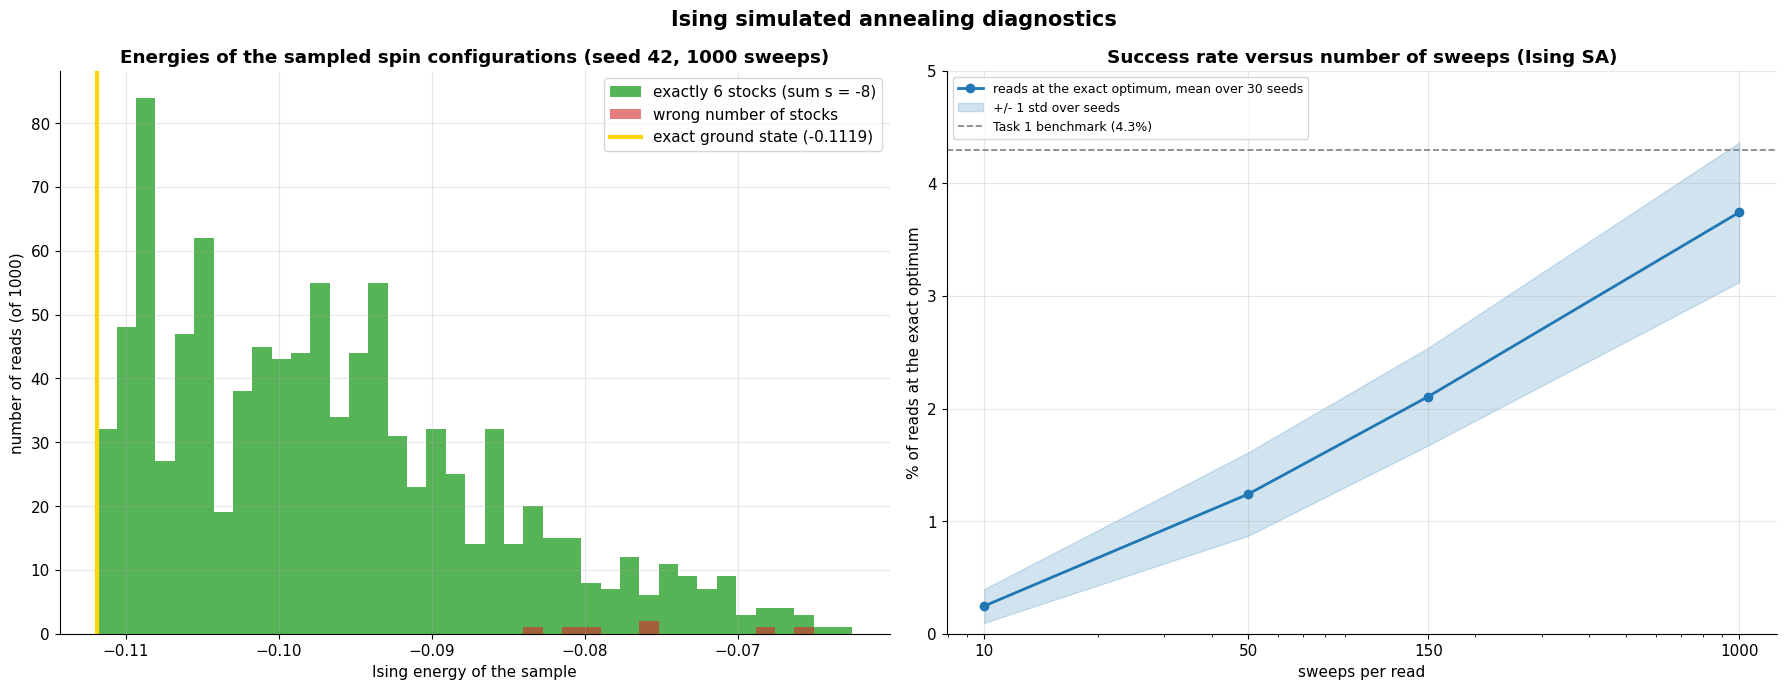

In [9]:
# STEP 7 | chart 2: energy histogram of the sampled Ising energies + success rate versus sweeps
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ax = axes[0]
bins = np.linspace(E_ising_reads.min(), np.percentile(E_ising_reads, 99), 40)
ax.hist(E_ising_reads[feas_i], bins=bins, color="#2ca02c", alpha=0.8, label=f"exactly {K} stocks (sum s = {MAGNETISATION})")
if (~feas_i).any():
    ax.hist(E_ising_reads[~feas_i], bins=bins, color="#d62728", alpha=0.6, label="wrong number of stocks")
ax.axvline(E_GS, color="gold", lw=3, label=f"exact ground state ({E_GS:.4f})")
ax.set_xlabel("Ising energy of the sample"); ax.set_ylabel(f"number of reads (of {NUM_READS})"); ax.grid(True, alpha=0.3); ax.legend()
ax.set_title(f"Energies of the sampled spin configurations (seed {SEED}, {NUM_SWEEPS} sweeps)", fontweight="bold")

ax = axes[1]
m = np.array([res_sweeps[s]["Reads at optimum (%)"].mean() for s in SWEEPS]); sd = np.array([res_sweeps[s]["Reads at optimum (%)"].std(ddof=1) for s in SWEEPS])
ax.plot(SWEEPS, m, marker="o", color="#1f77b4", lw=2, label="reads at the exact optimum, mean over 30 seeds")
ax.fill_between(SWEEPS, np.maximum(m - sd, 0), m + sd, color="#1f77b4", alpha=0.2, label="+/- 1 std over seeds")
ax.axhline(4.3, color="grey", ls="--", lw=1.2, label="Task 1 benchmark (4.3%)")
ax.set_xscale("log"); ax.set_xticks(SWEEPS); ax.set_xticklabels(SWEEPS)
ax.set_xlabel("sweeps per read"); ax.set_ylabel("% of reads at the exact optimum"); ax.grid(True, alpha=0.3)
ax.set_ylim(0, 5); ax.legend(loc="upper left", fontsize=9)
ax.set_title("Success rate versus number of sweeps (Ising SA)", fontweight="bold")
fig.suptitle("Ising simulated annealing diagnostics", fontsize=15, fontweight="bold")
plt.tight_layout(); savefig("ising_energy_histogram_and_sweeps"); plt.show()

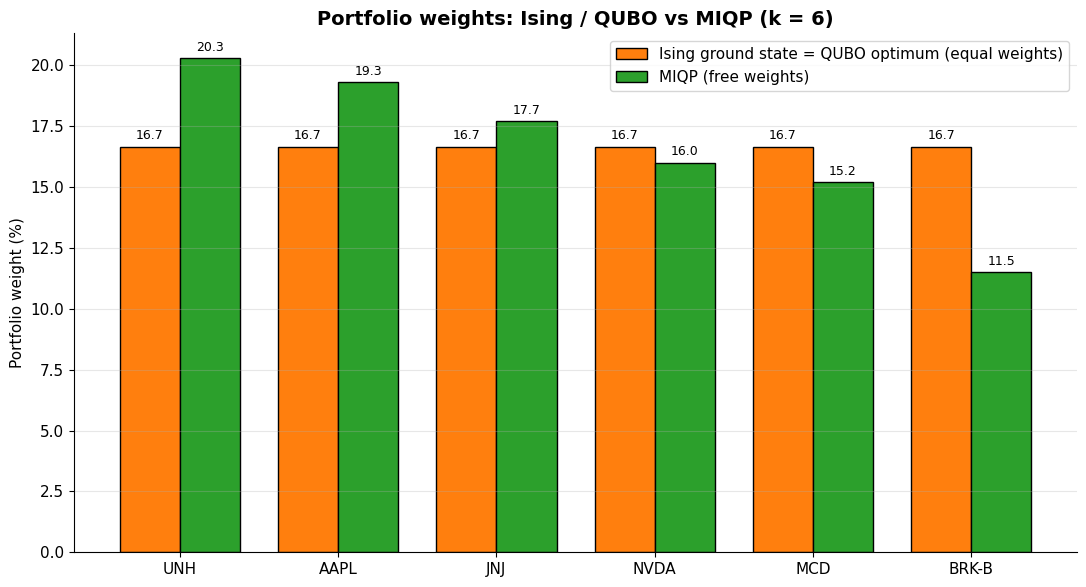

In [10]:
# STEP 7 | chart 3: weights, Ising / QUBO vs MIQP
stocks = list(MIQP_W)
w_is = [100 / K if t in [tickers[i] for i in sel_gs] else 0 for t in stocks]
w_mq = [MIQP_W[t] for t in stocks]
xp = np.arange(len(stocks)); bw = 0.38
fig, ax = plt.subplots(figsize=(11, 6))
b1 = ax.bar(xp - bw / 2, w_is, bw, color="#ff7f0e", edgecolor="black", label="Ising ground state = QUBO optimum (equal weights)")
b2 = ax.bar(xp + bw / 2, w_mq, bw, color="#2ca02c", edgecolor="black", label="MIQP (free weights)")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{b.get_height():.1f}", ha="center", fontsize=9)
ax.set_xticks(xp); ax.set_xticklabels(stocks); ax.set_ylabel("Portfolio weight (%)"); ax.grid(True, axis="y", alpha=0.3); ax.legend()
ax.set_title("Portfolio weights: Ising / QUBO vs MIQP (k = 6)", fontsize=14, fontweight="bold")
plt.tight_layout(); savefig("ising_weights_vs_miqp"); plt.show()

## Comparison table
Task 1 rows are taken from the Task 1 notebook (as listed in the roadmap). The highlighted rows are the Task 2 results.

In [15]:
# COMPARISON TABLE
def fmt(w_idx):
    return ", ".join(tickers[i] for i in w_idx)

rows = [
  ["MIQP (Gurobi, k = 6, free weights)", "UNH, AAPL, JNJ, NVDA, MCD, BRK-B (20.3 / 19.3 / 17.7 / 16.0 / 15.2 / 11.5%)", 22.76, 21.15, 1.076, -0.1126],
  ["QUBO + own SA (k = 6)", "AAPL, NVDA, MCD, JNJ, UNH, BRK-B (16.67% each)", 22.26, 20.75, 1.073, -0.1119],
  ["QUBO + D-Wave local SA", f"same six stocks (optimum in {hit_q.mean() * 100:.1f}% of reads)", 22.26, 20.75, 1.073, -0.1119],
  ["Ising + exhaustive search", f"{fmt(sel_gs)} ({100 / K:.2f}% each)", r_e * 100, s_e * 100, sh_e, F_EX],
  ["Ising + simulated annealing", f"{fmt(np.flatnonzero(X_ising[best_i]))} ({100 / K:.2f}% each; optimum in {hit_i.mean() * 100:.1f}% of reads, seed {SEED})",
   r_i * 100, s_i * 100, sh_i, obj_best_i],
]
cmp = pd.DataFrame(rows, columns=["Method", "Portfolio", "Return %", "Vol %", "Sharpe", "Objective"]).set_index("Method")
cmp.to_csv(f"{OUT_DIR}/task2_comparison_table.csv")
def hl(row): return ["background-color: #fff2a8" if row.name.startswith("Ising") else "" for _ in row]
display(cmp.style.format({"Return %": "{:.2f}", "Vol %": "{:.2f}", "Sharpe": "{:.3f}", "Objective": "{:.4f}"})
        .set_properties(subset=["Portfolio"], **{"text-align": "left"}))

,Portfolio,Return %,Vol %,Sharpe,Objective
Method,,,,,
"MIQP (Gurobi, k = 6, free weights)","UNH, AAPL, JNJ, NVDA, MCD, BRK-B (20.3 / 19.3 / 17.7 / 16.0 / 15.2 / 11.5%)",22.76,21.15,1.076,-0.1126
QUBO + own SA (k = 6),"AAPL, NVDA, MCD, JNJ, UNH, BRK-B (16.67% each)",22.26,20.75,1.073,-0.1119
QUBO + D-Wave local SA,same six stocks (optimum in 4.3% of reads),22.26,20.75,1.073,-0.1119
Ising + exhaustive search,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B (16.67% each)",22.26,20.75,1.073,-0.1119
Ising + simulated annealing,"AAPL, NVDA, MCD, JNJ, UNH, BRK-B (16.67% each; optimum in 3.2% of reads, seed 42)",22.26,20.75,1.073,-0.1119


## Step 8 – Conclusions

In [12]:
# STEP 8 | conclusions (numbers are filled in from the results above)
mi, mq = res_ising["Reads at optimum (%)"], res_qubo["Reads at optimum (%)"]
t_i, t_q = res_ising["Runtime (s)"].mean(), res_qubo["Runtime (s)"].mean()
p1 = tab_P.iloc[1]; p05 = tab_P.iloc[0]; p2 = tab_P.iloc[2]
sw10, sw1000 = tab_sweeps.loc[10], tab_sweeps.loc[1000]
SEEDCOL = f"Seeds whose best read is optimal (of {len(SEEDS)})"
display(Markdown(f"""
**1. Ising and QUBO are the same problem.** The Ising Hamiltonian built with dimod and with the hand-coded formulas agree (differences below 1e-12), the Ising energy equals the QUBO energy on all {2 ** N:,} states (max difference {max_diff:.1e}) and equals the Markowitz objective on the {len(combos):,} feasible states. The exact ground state (sum of spins = {MAGNETISATION}) is **{fmt(sel_gs)}** at {100 / K:.2f}% each, with energy / objective {F_EX:.4f}, return {r_e * 100:.2f}%, volatility {s_e * 100:.2f}%, Sharpe {sh_e:.3f}. This is the same six stocks and the same objective (-0.1119) as the Task 1 QUBO optimum, so the conversion is correct.

**2. The spin-glass picture.** All {len(iu[0])} couplings J_ij are positive (antiferromagnetic: covariance plus penalty), all {N} local fields h_i are positive (they favour spin down), and {frustrated} of the {len(list(itertools.combinations(range(N), 3)))} triangles are frustrated. The model is fully connected and frustrated, a Sherrington-Kirkpatrick-type spin glass with a fixed-magnetisation constraint.

**3. Solver behaviour.** With the same budget as the Task 1 D-Wave local SA (1000 reads x 1000 sweeps, 30 seeds) the Ising SA hit the exact optimum in {mi.mean():.1f}% of reads on average (std {mi.std(ddof=1):.1f}, range {mi.min():.1f}-{mi.max():.1f}) against {mq.mean():.1f}% (std {mq.std(ddof=1):.1f}) for the QUBO model with the same seeds; the Task 1 single run (seed {SEED}) gave {hit_q.mean() * 100:.1f}%, the Ising run with the same seed {hit_i.mean() * 100:.1f}%. The best of the 1000 reads was the exact optimum in {int(res_ising["Best read = optimum"].sum())} of {len(SEEDS)} seeds (QUBO: {int(res_qubo["Best read = optimum"].sum())} of {len(SEEDS)}). Feasible reads (exactly {K} stocks): {res_ising["Feasible reads (%)"].mean():.1f}% (Ising) and {res_qubo["Feasible reads (%)"].mean():.1f}% (QUBO). Runtime per run: {t_i:.2f} s (Ising) and {t_q:.2f} s (QUBO).

**4. Sensitivity.** Sweeps: with 10 sweeps {sw10["Reads at optimum % (mean)"]:.2f}% of reads hit the optimum and {sw10[SEEDCOL]:.0f} of {len(SEEDS)} seeds found it at least once; with 1000 sweeps {sw1000["Reads at optimum % (mean)"]:.2f}% and {sw1000[SEEDCOL]:.0f} of {len(SEEDS)} seeds. Penalty (1000 sweeps): reads at the optimum {p05["Reads at optimum % (mean)"]:.2f}% / {p1["Reads at optimum % (mean)"]:.2f}% / {p2["Reads at optimum % (mean)"]:.2f}% and feasible reads {p05["Feasible reads % (mean)"]:.1f}% / {p1["Feasible reads % (mean)"]:.1f}% / {p2["Feasible reads % (mean)"]:.1f}% for 0.5x / 1x / 2x P (a smaller P gave a higher hit rate and a larger P a lower one, while the feasible fraction stayed above 99%).

**5. Weight model.** MIQP (free weights) has a slightly better objective, -0.1126 against {F_EX:.4f} for the equal-weight Ising / QUBO portfolio (Sharpe 1.076 against {sh_e:.3f}); this difference comes from the weight model, not from the Ising formulation. The free-weight Ising model (QUBO-W) is not part of this notebook.

**6. Scale.** At N = 20 every method finishes in seconds (exhaustive enumeration of the {len(combos):,} feasible states takes {t_exact * 1000:.0f} ms in total), so any advantage of Ising-type solvers would only appear for larger universes.
"""))


**1. Ising and QUBO are the same problem.** The Ising Hamiltonian built with dimod and with the hand-coded formulas agree (differences below 1e-12), the Ising energy equals the QUBO energy on all 1,048,576 states (max difference 4.4e-15) and equals the Markowitz objective on the 38,760 feasible states. The exact ground state (sum of spins = -8) is **AAPL, NVDA, MCD, JNJ, UNH, BRK-B** at 16.67% each, with energy / objective -0.1119, return 22.26%, volatility 20.75%, Sharpe 1.073. This is the same six stocks and the same objective (-0.1119) as the Task 1 QUBO optimum, so the conversion is correct.

**2. The spin-glass picture.** All 190 couplings J_ij are positive (antiferromagnetic: covariance plus penalty), all 20 local fields h_i are positive (they favour spin down), and 1140 of the 1140 triangles are frustrated. The model is fully connected and frustrated, a Sherrington-Kirkpatrick-type spin glass with a fixed-magnetisation constraint.

**3. Solver behaviour.** With the same budget as the Task 1 D-Wave local SA (1000 reads x 1000 sweeps, 30 seeds) the Ising SA hit the exact optimum in 3.7% of reads on average (std 0.6, range 3.0-5.1) against 3.9% (std 0.4) for the QUBO model with the same seeds; the Task 1 single run (seed 42) gave 4.3%, the Ising run with the same seed 3.2%. The best of the 1000 reads was the exact optimum in 30 of 30 seeds (QUBO: 30 of 30). Feasible reads (exactly 6 stocks): 99.2% (Ising) and 99.3% (QUBO). Runtime per run: 0.39 s (Ising) and 0.37 s (QUBO).

**4. Sensitivity.** Sweeps: with 10 sweeps 0.25% of reads hit the optimum and 29 of 30 seeds found it at least once; with 1000 sweeps 3.74% and 30 of 30 seeds. Penalty (1000 sweeps): reads at the optimum 15.09% / 3.74% / 0.43% and feasible reads 99.4% / 99.2% / 99.2% for 0.5x / 1x / 2x P (a smaller P gave a higher hit rate and a larger P a lower one, while the feasible fraction stayed above 99%).

**5. Weight model.** MIQP (free weights) has a slightly better objective, -0.1126 against -0.1119 for the equal-weight Ising / QUBO portfolio (Sharpe 1.076 against 1.073); this difference comes from the weight model, not from the Ising formulation. The free-weight Ising model (QUBO-W) is not part of this notebook.

**6. Scale.** At N = 20 every method finishes in seconds (exhaustive enumeration of the 38,760 feasible states takes 37 ms in total), so any advantage of Ising-type solvers would only appear for larger universes.
